<a href="https://colab.research.google.com/github/mercymaraba/synthetic-biodata-sandbox/blob/main/Synthetic_Biodata_Sandbox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Synthetic Biodata Sandbox: Generating Privacy-Preserving Lab Records

**Author:** Mercy Jerobon Maraba

Patient lab data is useful for research and training, but it is hard to share because it belongs to real people. This project generates synthetic full blood count records and tests whether they are realistic, useful for analysis, safe from re-identification, and clinically believable to a lab scientist.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.neighbors import NearestNeighbors

SEED = 101
N_PER_SPLIT = 1000          # train / holdout / reference, 1,000 patients each
RUNS = 3                    # repeat with different random splits

CONTINUOUS = ["age", "hb", "wbc", "platelets", "mcv", "lymph_pct", "blast_pct"]
CATEGORICAL = ["sex", "diagnosis"]
COLUMNS = ["age", "sex", "diagnosis", "hb", "wbc", "platelets", "mcv", "lymph_pct", "blast_pct"]
DIAGNOSIS_MIX = {"Normal": 0.35, "Iron deficiency anaemia": 0.22, "Malaria": 0.20, "AML": 0.12, "CLL": 0.11}
DIAGNOSES = list(DIAGNOSIS_MIX)



# STEP 1: SIMULATED SENSITIVE SOURCE COHORT (FULL BLOOD COUNT PANEL)
No real patient data is used. Values are generated per diagnosis so the
data has real clinical structure: low MCV in iron deficiency, low platelets
in malaria, high WBC and blasts together in AML, lymphocytosis in CLL.

In [ ]:
def _group(rng, dx, n):
    sex = rng.choice(["F", "M"], size=n, p=[0.55, 0.45] if dx == "Iron deficiency anaemia" else [0.5, 0.5])
    male = (sex == "M").astype(float)
    lognorm = lambda median, sigma: rng.lognormal(np.log(median), sigma, n)

    if dx == "Normal":
        age = rng.normal(38, 14, n); hb = rng.normal(13.3 + 1.6 * male, 1.0)
        wbc = lognorm(6.5, 0.25); plt_ = rng.normal(265, 55, n); mcv = rng.normal(88, 4, n)
        lymph = rng.normal(32, 7, n); blast = np.zeros(n)
    elif dx == "Iron deficiency anaemia":
        age = rng.normal(34, 13, n); sev = rng.beta(2, 3, n)
        hb = 11.5 - 5.0 * sev + 0.8 * male + rng.normal(0, 0.6, n)
        mcv = 79 - 15 * sev + rng.normal(0, 3, n)
        wbc = lognorm(6.2, 0.25); plt_ = rng.normal(330, 80, n) + 80 * sev
        lymph = rng.normal(31, 7, n); blast = np.zeros(n)
    elif dx == "Malaria":
        age = rng.gamma(2.2, 12, n) + 2; load = rng.beta(2, 4, n)
        hb = 12.5 + 0.8 * male - 4.5 * load + rng.normal(0, 0.9, n)
        plt_ = lognorm(120, 0.35) * (1.2 - 0.7 * load)
        wbc = lognorm(5.8, 0.3); mcv = rng.normal(86, 5, n)
        lymph = rng.normal(26, 8, n); blast = np.zeros(n)
    elif dx == "AML":
        age = rng.normal(56, 14, n); burden = rng.beta(2, 2, n)
        blast = 20 + 70 * burden + rng.normal(0, 4, n)
        wbc = lognorm(8, 0.6) * np.exp(2.2 * burden)
        hb = 9.8 - 2.8 * burden + rng.normal(0, 0.9, n)
        plt_ = lognorm(70, 0.45) * (1.1 - 0.7 * burden)
        mcv = rng.normal(92, 6, n); lymph = rng.normal(15, 6, n)
    else:  # CLL
        age = rng.normal(68, 9, n); stage = rng.beta(2, 3, n)
        wbc = lognorm(22, 0.35) * np.exp(1.6 * stage)
        lymph = 65 + 25 * stage + rng.normal(0, 4, n)
        hb = 13.0 + 0.8 * male - 3.0 * stage + rng.normal(0, 0.8, n)
        plt_ = rng.normal(210, 50, n) * (1.1 - 0.5 * stage)
        mcv = rng.normal(90, 4, n); blast = np.clip(rng.exponential(0.8, n), 0, 4)

    return pd.DataFrame({"age": age, "sex": sex, "diagnosis": dx, "hb": hb, "wbc": wbc,
                         "platelets": plt_, "mcv": mcv, "lymph_pct": lymph, "blast_pct": blast})


def simulate_cohort(n, seed):
    rng = np.random.default_rng(seed)
    counts = rng.multinomial(n, list(DIAGNOSIS_MIX.values()))
    df = pd.concat([_group(rng, dx, k) for dx, k in zip(DIAGNOSES, counts)], ignore_index=True)
    # Round and bound values the way a haematology analyser would report them
    df["age"] = df["age"].clip(1, 95).round()
    df["hb"] = df["hb"].clip(3.5, 19.5).round(1)
    df["wbc"] = df["wbc"].clip(0.8, 400).round(2)
    df["platelets"] = df["platelets"].clip(5, 900).round()
    df["mcv"] = df["mcv"].clip(55, 115).round(1)
    df["lymph_pct"] = df["lymph_pct"].clip(2, 98).round(1)
    df["blast_pct"] = df["blast_pct"].clip(0, 98).round(1)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)[COLUMNS]


def tidy(df):
    """Round to analyser precision. No clipping, so impossible values stay visible."""
    df = df.copy()
    df["age"] = df["age"].round(); df["platelets"] = df["platelets"].round()
    for c in ["hb", "mcv", "lymph_pct", "blast_pct"]:
        df[c] = df[c].round(1)
    df["wbc"] = df["wbc"].round(2)
    return df[COLUMNS]


cohort = simulate_cohort(3 * N_PER_SPLIT, SEED)
print("[✓] Simulated sensitive cohort created.")
print(f"    {len(cohort)} patients, {len(COLUMNS)} variables, {cohort.diagnosis.nunique()} diagnoses.\n")
print(cohort.groupby("diagnosis")[["age", "hb", "wbc", "platelets", "mcv", "lymph_pct", "blast_pct"]]
      .median().round(1).to_string(), "\n")



[✓] Simulated sensitive cohort created.
    3000 patients, 9 variables, 5 diagnoses.

                          age    hb   wbc  platelets   mcv  lymph_pct  blast_pct
diagnosis                                                                       
AML                      56.0   8.6  22.8       53.0  92.1       14.9       53.4
CLL                      67.0  12.3  41.7      190.0  90.2       74.6        0.6
Iron deficiency anaemia  34.0   9.9   6.3      363.0  73.1       30.8        0.0
Malaria                  23.0  11.4   5.8      116.0  86.2       26.2        0.0
Normal                   39.0  14.0   6.4      268.0  88.0       31.9        0.0 



## Step 2: Synthetic data generators

Here I build four ways of creating synthetic patients. Each one learns only from the training data, so the holdout patients stay unseen for the privacy tests later.

* **Independent KDE:** my original approach. It copies the shape of each column on its own, but loses the links between them.
* **Gaussian copula:** keeps the overall correlations between lab values across the whole cohort.
* **Stratified copula:** builds a separate copula for each diagnosis, so AML, malaria, iron deficiency and the others each keep their own blood count pattern.
* **Noisy copy (unsafe):** real patients with a little noise added. I included it on purpose as a bad example that the privacy tests should catch.

In [ ]:
class IndependentKDE:
    """Baseline (the original prototype): one KDE per column, sampled separately.
    Keeps each column's shape but breaks every link between columns."""
    name = "Independent KDE"
    def __init__(self, seed): self.rng = np.random.default_rng(seed)
    def fit(self, train):
        self.kdes = {c: stats.gaussian_kde(train[c].astype(float)) for c in CONTINUOUS}
        self.freqs = {c: train[c].value_counts(normalize=True) for c in CATEGORICAL}
        return self
    def sample(self, n):
        out = {c: k.resample(n, seed=self.rng).ravel() for c, k in self.kdes.items()}
        for c, f in self.freqs.items():
            out[c] = self.rng.choice(f.index.to_numpy(), size=n, p=f.to_numpy())
        return tidy(pd.DataFrame(out))


class GaussianCopula:
    """Each column is mapped to a normal score through its empirical distribution,
    the correlation between scores is learned, then new scores are sampled and
    mapped back. Keeps correlations and never goes outside the observed range."""
    name = "Gaussian copula"
    def __init__(self, seed): self.rng = np.random.default_rng(seed)

    def _to_uniform(self, df):
        U = pd.DataFrame(index=df.index)
        for c in self.cols:
            if c in CATEGORICAL:   # each category gets its own slice of (0, 1)
                lo, hi = self.cat_bounds[c]
                codes = df[c].map(lo).to_numpy()
                width = df[c].map(hi).to_numpy() - codes
                U[c] = codes + width * self.rng.uniform(0.05, 0.95, len(df))
            else:
                U[c] = stats.rankdata(df[c], method="average") / (len(df) + 1)
        return U

    def fit(self, train):
        self.cols = [c for c in COLUMNS if c in train.columns and train[c].nunique() > 1]
        self.constant = {c: train[c].iloc[0] for c in COLUMNS if c in train.columns and c not in self.cols}
        self.cat_bounds = {}
        for c in CATEGORICAL:
            if c in self.cols:
                p = train[c].value_counts(normalize=True)
                edges = np.r_[0, p.cumsum().to_numpy()]
                self.cat_bounds[c] = (dict(zip(p.index, edges[:-1])), dict(zip(p.index, edges[1:])))
        self.values = {c: np.sort(train[c].to_numpy(float)) for c in self.cols if c in CONTINUOUS}
        Z = stats.norm.ppf(self._to_uniform(train).clip(1e-6, 1 - 1e-6))
        self.corr = np.corrcoef(Z, rowvar=False) + 1e-6 * np.eye(len(self.cols))
        return self

    def sample(self, n):
        Z = self.rng.multivariate_normal(np.zeros(len(self.cols)), self.corr, n)
        U = stats.norm.cdf(Z)
        out = {}
        for j, c in enumerate(self.cols):
            if c in CATEGORICAL:
                lo, _ = self.cat_bounds[c]
                cats, starts = list(lo), np.array(list(lo.values()))
                out[c] = np.array(cats)[np.searchsorted(starts, U[:, j], side="right") - 1]
            else:
                v = self.values[c]
                out[c] = np.interp(U[:, j], np.linspace(0, 1, len(v)), v)
        for c, val in self.constant.items():
            out[c] = np.full(n, val)
        return pd.DataFrame(out)[COLUMNS]


class StratifiedCopula:
    """A separate Gaussian copula inside each diagnosis group, so AML, malaria,
    iron deficiency and so on each keep their own lab profile."""
    name = "Stratified copula"
    def __init__(self, seed): self.seed = seed; self.rng = np.random.default_rng(seed)
    def fit(self, train):
        self.freq = train["diagnosis"].value_counts(normalize=True)
        self.models = {dx: GaussianCopula(self.seed + i).fit(g)
                       for i, (dx, g) in enumerate(train.groupby("diagnosis"))}
        return self
    def sample(self, n):
        counts = self.rng.multinomial(n, self.freq.to_numpy())
        parts = [self.models[dx].sample(k) for dx, k in zip(self.freq.index, counts) if k > 0]
        return tidy(pd.concat(parts, ignore_index=True).sample(frac=1, random_state=self.seed))


class NoisyCopy:
    """Deliberately UNSAFE negative control: real rows plus a little noise.
    The privacy tests must flag it, otherwise the tests are not working."""
    name = "Noisy copy (unsafe)"
    def __init__(self, seed): self.rng = np.random.default_rng(seed)
    def fit(self, train):
        self.train = train.reset_index(drop=True); self.sd = train[CONTINUOUS].std(); return self
    def sample(self, n):
        out = self.train.iloc[self.rng.integers(0, len(self.train), n)].reset_index(drop=True).copy()
        for c in CONTINUOUS:
            out[c] = out[c] + self.rng.normal(0, 0.02 * self.sd[c], n)
        return tidy(out)


# Wrap the global copula output in tidy() too
class GlobalCopula(GaussianCopula):
    def sample(self, n): return tidy(super().sample(n))


GENERATORS = [IndependentKDE, GlobalCopula, StratifiedCopula, NoisyCopy]



## Step 3: Evaluation metrics

Here I set up the tests that every synthetic dataset has to pass. Each one is scored on four questions:

* **Fidelity:** do the synthetic values and the links between them look like the real data? This includes checking that synthetic AML patients actually have AML-like blood counts.
* **Utility:** if I train a model to predict diagnosis on the synthetic data, does it still work on real patients it has never seen?
* **Privacy:** are the synthetic records any closer to the training patients than unseen patients are? A membership inference attack tries to guess who was in the training data.
* **Plausibility:** would a lab scientist accept each record? I check for impossible values (like negative blast counts) and clinical rules (like AML needing at least 20% blasts).

In [ ]:
def fidelity(real, synth):
    ks = np.mean([stats.ks_2samp(real[c], synth[c]).statistic for c in CONTINUOUS])
    rc, sc = real[CONTINUOUS].corr("spearman"), synth[CONTINUOUS].corr("spearman")
    gap = (rc - sc).abs().to_numpy()[np.triu_indices(len(CONTINUOUS), 1)]
    # Do synthetic AML patients have AML-like counts? (same for every diagnosis)
    cond = []
    for dx in DIAGNOSES:
        r, s = real[real.diagnosis == dx], synth[synth.diagnosis == dx]
        for c in CONTINUOUS[1:]:
            cond.append(stats.ks_2samp(r[c], s[c]).statistic if len(s) > 5 else 1.0)
    return {"marginal_ks": ks, "correlation_gap": np.nanmean(gap), "conditional_ks": np.mean(cond)}


def utility(synth, holdout, seed):
    """Train on synthetic, test on real (TSTR): predict diagnosis from the blood count."""
    def xy(d):
        X = d[CONTINUOUS].astype(float).assign(male=(d.sex == "M").astype(float)).fillna(0)
        return X.to_numpy(), d.diagnosis.to_numpy()
    clf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1).fit(*xy(synth))
    Xh, yh = xy(holdout)
    return {"tstr_f1": f1_score(yh, clf.predict(Xh), average="macro", labels=DIAGNOSES, zero_division=0)}


def privacy(train, holdout, synth):
    """Synthetic records should be no closer to training patients than unseen patients are."""
    raw = lambda d: d[CONTINUOUS].astype(float).assign(
        wbc=np.log1p(d.wbc.clip(lower=0)), platelets=np.log1p(d.platelets.clip(lower=0)))
    mu, sd = raw(train).mean(), raw(train).std().replace(0, 1)
    def enc(d):
        X = (raw(d) - mu) / sd
        X["male"] = (d.sex == "M").astype(float)
        for dx in DIAGNOSES:
            X[dx] = (d.diagnosis == dx).astype(float)
        return X.fillna(0).to_numpy()
    T, H, S = enc(train), enc(holdout), enc(synth)
    nn = lambda ref, q: NearestNeighbors(n_neighbors=1).fit(ref).kneighbors(q)[0].ravel()

    d_st, d_sh, d_ht = nn(T, S), nn(H, S), nn(T, H)
    # Membership inference attack: guess "was in training" if close to a synthetic record
    scores = -np.r_[nn(S, T), nn(S, H)]
    labels = np.r_[np.ones(len(T)), np.zeros(len(H))]
    return {"dcr_share": np.mean(d_st < d_sh),                         # 0.5 is ideal
            "near_copy_rate": np.mean(d_st < np.percentile(d_ht, 5)),  # about 0.05 is ideal
            "mia_auc": roc_auc_score(labels, scores)}                  # 0.5 is ideal


RANGES = {"age": (0, 110), "hb": (2, 22), "wbc": (0.1, 500), "platelets": (1, 1500),
          "mcv": (50, 130), "lymph_pct": (0, 100), "blast_pct": (0, 100)}
RULES = {
    "Blasts >= 20% but not AML": lambda d: (d.blast_pct >= 20) & (d.diagnosis != "AML"),
    "AML with blasts < 20%": lambda d: (d.diagnosis == "AML") & (d.blast_pct < 20),
    "Blasts in non-leukaemia patient": lambda d: d.diagnosis.isin(["Normal", "Iron deficiency anaemia", "Malaria"]) & (d.blast_pct > 1),
    "Normal with Hb < 10 g/dL": lambda d: (d.diagnosis == "Normal") & (d.hb < 10),
    "CLL without lymphocytosis": lambda d: (d.diagnosis == "CLL") & (d.lymph_pct < 50),
    "Iron deficiency with MCV > 90 fL": lambda d: (d.diagnosis == "Iron deficiency anaemia") & (d.mcv > 90),
}


def plausibility(synth):
    out_of_range = np.zeros(len(synth), bool)
    for c, (lo, hi) in RANGES.items():
        out_of_range |= ((synth[c] < lo) | (synth[c] > hi)).to_numpy()
    clinical = pd.DataFrame({k: f(synth) for k, f in RULES.items()}).any(axis=1)
    return {"impossible_values": out_of_range.mean(), "clinically_inconsistent": clinical.mean()}


def evaluate(train, holdout, synth, seed):
    return {**fidelity(train, synth), **utility(synth, holdout, seed),
            **privacy(train, holdout, synth), **plausibility(synth)}



## Step 4: Run the experiment

I run the whole comparison three times, each time with a new random split of the 3,000 patients into training, holdout and reference groups of 1,000. The reference group is real data scored as if it were synthetic, so it shows what a perfect generator would score.

In [ ]:
rows, examples = [], {}
for run in range(RUNS):
    s = cohort.sample(frac=1, random_state=run).reset_index(drop=True)
    train, holdout, reference = s[:N_PER_SPLIT], s[N_PER_SPLIT:2 * N_PER_SPLIT], s[2 * N_PER_SPLIT:]
    rows.append({"run": run, "method": "Real data (reference)", **evaluate(train, holdout, reference, run)})
    if run == 0:
        examples["Real data"] = train
    for G in GENERATORS:
        synth = G(seed=run).fit(train).sample(N_PER_SPLIT)
        rows.append({"run": run, "method": G.name, **evaluate(train, holdout, synth, run)})
        if run == 0:
            examples[G.name] = synth
    print(f"[✓] Run {run + 1} of {RUNS} complete.")

results = pd.DataFrame(rows)
order = ["Real data (reference)"] + [G.name for G in GENERATORS]
summary = results.groupby("method").mean(numeric_only=True).drop(columns="run").reindex(order)

pd.set_option("display.width", 200)
print("\n" + "=" * 100)
print("                 SYNTHETIC BIODATA SANDBOX: EVALUATION REPORT (mean of runs)")
print("=" * 100)
print(summary.round(3).to_string())
print("-" * 100)
print("Fidelity:     marginal_ks, correlation_gap, conditional_ks   -> lower is better")
print("Utility:      tstr_f1 (train on synthetic, test on real)     -> higher is better")
print("Privacy:      dcr_share and mia_auc near 0.5, near_copy_rate near 0.05")
print("Plausibility: impossible_values, clinically_inconsistent     -> lower is better")
print("=" * 100)

# Pass / fail verdict per generator
ref = summary.loc["Real data (reference)"]
print("\nVERDICT")
for m in order[1:]:
    r = summary.loc[m]
    private = r.mia_auc < 0.6 and r.near_copy_rate < 0.15
    useful = r.tstr_f1 >= ref.tstr_f1 - 0.10
    plausible = r.impossible_values < 0.01 and r.clinically_inconsistent < 0.05
    flags = [("PRIVATE" if private else "LEAKS PATIENTS"),
             ("USEFUL" if useful else "LOW UTILITY"),
             ("PLAUSIBLE" if plausible else "IMPLAUSIBLE RECORDS")]
    tick = "✓" if all([private, useful, plausible]) else "✗"
    print(f"  [{tick}] {m:<22} {' | '.join(flags)}")



[✓] Run 1 of 3 complete.
[✓] Run 2 of 3 complete.
[✓] Run 3 of 3 complete.

                 SYNTHETIC BIODATA SANDBOX: EVALUATION REPORT (mean of runs)
                       marginal_ks  correlation_gap  conditional_ks  tstr_f1  dcr_share  near_copy_rate  mia_auc  impossible_values  clinically_inconsistent
method                                                                                                                                                      
Real data (reference)        0.040            0.034           0.089    0.973      0.499           0.061    0.512              0.000                    0.000
Independent KDE              0.118            0.298           0.484    0.134      0.501           0.000    0.513              0.499                    0.651
Gaussian copula              0.030            0.055           0.355    0.507      0.506           0.013    0.519              0.000                    0.273
Stratified copula            0.027            0.023           

## Step 5: Figures

These charts show the results visually.

In [ ]:
sns.set_style("whitegrid")
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#a3a29c"



### Figure 1: Does each generator keep the link between diagnosis and blood counts?

In real data, AML patients (blue) sit above the 20% blast line. A good generator should keep that pattern.

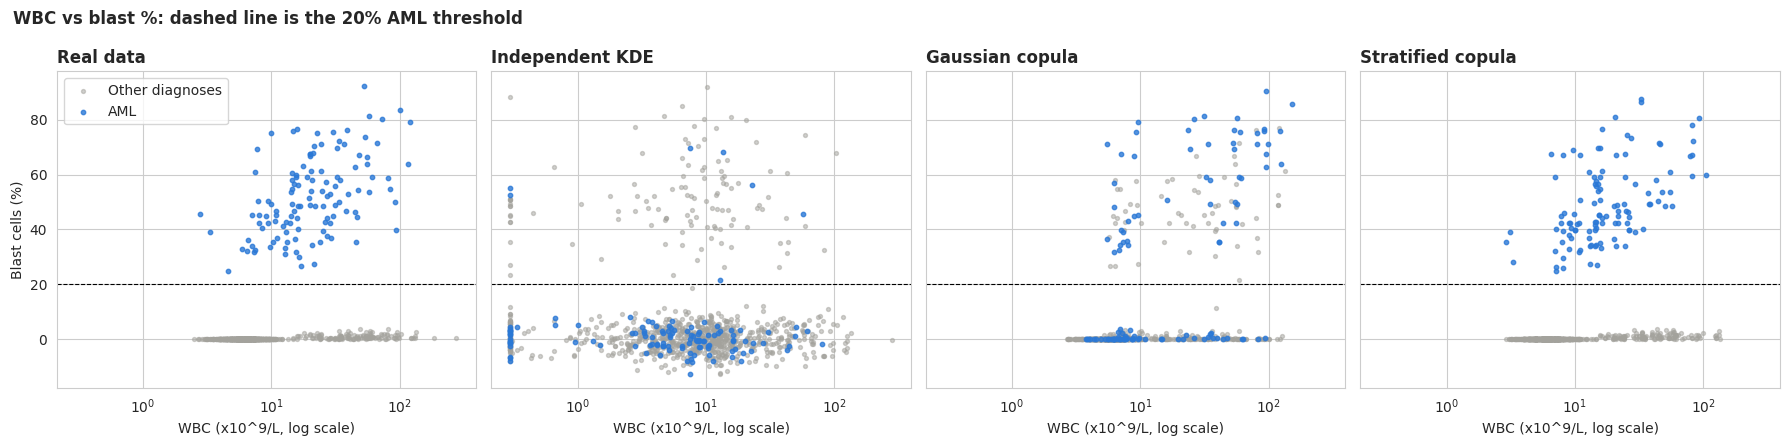

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, ["Real data", "Independent KDE", "Gaussian copula", "Stratified copula"]):
    d = examples[name]; aml = d.diagnosis == "AML"
    ax.scatter(d.wbc[~aml].clip(lower=0.3), d.blast_pct[~aml], s=8, c=GREY, alpha=0.5, label="Other diagnoses")
    ax.scatter(d.wbc[aml].clip(lower=0.3), d.blast_pct[aml], s=10, c=BLUE, alpha=0.8, label="AML")
    ax.axhline(20, ls="--", c="black", lw=0.8)
    ax.set_xscale("log"); ax.set_title(name, fontweight="bold", loc="left")
    ax.set_xlabel("WBC (x10^9/L, log scale)")
axes[0].set_ylabel("Blast cells (%)"); axes[0].legend(loc="upper left")
fig.suptitle("WBC vs blast %: dashed line is the 20% AML threshold", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig("fig1_structure.png", dpi=200); plt.show()



### Figure 2: Privacy vs utility

The best generators sit in the top left: useful, and no easier to attack than real unseen patients. The shaded area means an attacker can guess who was in the training data.

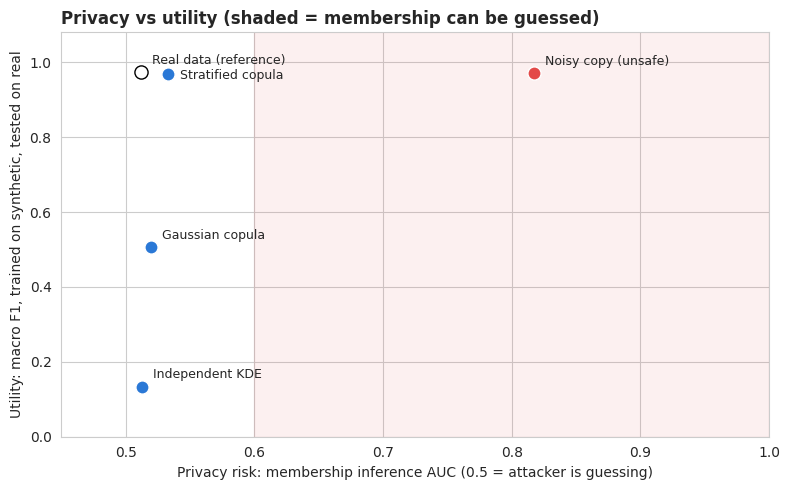

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.axvspan(0.6, 1.0, color=RED, alpha=0.08)
for m, r in summary.iterrows():
    colour = RED if "unsafe" in m else ("white" if m.startswith("Real") else BLUE)
    ax.scatter(r.mia_auc, r.tstr_f1, s=90, c=colour, edgecolors="black" if m.startswith("Real") else "white", zorder=3)
    ax.annotate(m, (r.mia_auc, r.tstr_f1), xytext=(8, -4 if m.startswith("Strat") else 6), textcoords="offset points", fontsize=9)
ax.set_xlim(0.45, 1.0); ax.set_ylim(0, 1.08)
ax.set_xlabel("Privacy risk: membership inference AUC (0.5 = attacker is guessing)")
ax.set_ylabel("Utility: macro F1, trained on synthetic, tested on real")
ax.set_title("Privacy vs utility (shaded = membership can be guessed)", fontweight="bold", loc="left")
plt.tight_layout(); plt.savefig("fig2_privacy_utility.png", dpi=200); plt.show()



### Figure 3: Would a lab scientist accept these records?

Share of synthetic records with impossible values or clinically inconsistent results.

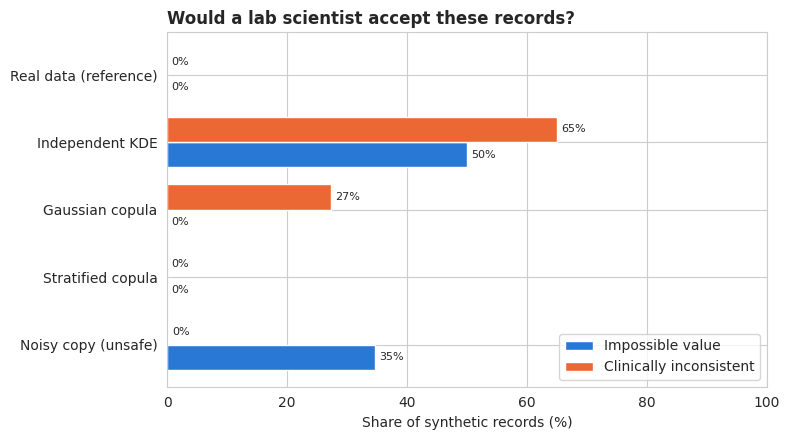

In [ ]:
p = (summary[["impossible_values", "clinically_inconsistent"]] * 100).iloc[::-1]
ax = p.plot.barh(figsize=(8, 4.5), color=[BLUE, ORANGE], width=0.75)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f%%", padding=3, fontsize=8)
ax.set_xlabel("Share of synthetic records (%)"); ax.set_xlim(0, 100); ax.set_ylabel("")
ax.legend(["Impossible value", "Clinically inconsistent"], loc="lower right")
ax.set_title("Would a lab scientist accept these records?", fontweight="bold", loc="left")
plt.tight_layout(); plt.savefig("fig3_plausibility.png", dpi=200); plt.show()



### Figure 4: Blast % distribution

My original method creates negative blast percentages, which are impossible in a real lab.

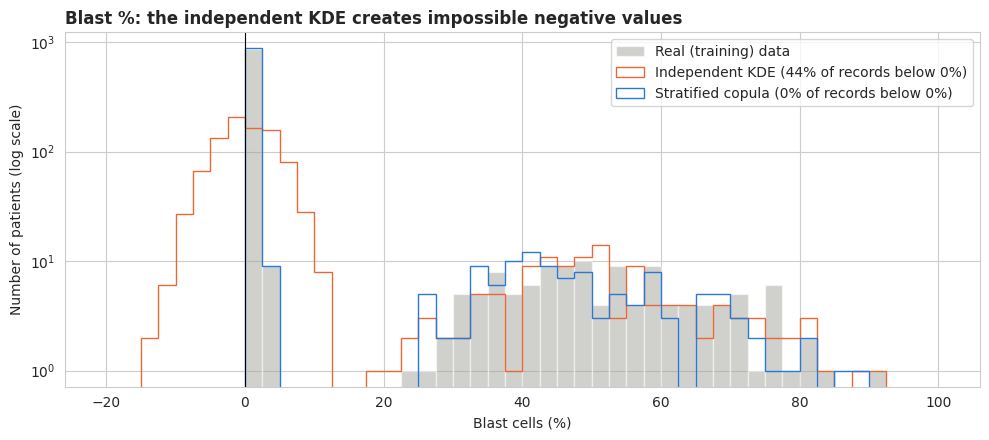

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(-20, 101, 2.5)
ax.hist(examples["Real data"].blast_pct, bins=bins, color=GREY, alpha=0.5, label="Real (training) data")
for name, col in [("Independent KDE", ORANGE), ("Stratified copula", BLUE)]:
    neg = (examples[name].blast_pct < 0).mean()
    ax.hist(examples[name].blast_pct, bins=bins, histtype="step", lw=2, color=col,
            label=f"{name} ({neg:.0%} of records below 0%)")
ax.axvline(0, c="black", lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("Blast cells (%)"); ax.set_ylabel("Number of patients (log scale)"); ax.legend()
ax.set_title("Blast %: the independent KDE creates impossible negative values", fontweight="bold", loc="left")
plt.tight_layout(); plt.savefig("fig4_blast_distribution.png", dpi=200); plt.show()



## Step 6: Export the synthetic dataset

The stratified copula was the only generator that passed all three checks, so I use it to create the final synthetic dataset.

In [ ]:
best = StratifiedCopula(seed=0).fit(cohort.sample(frac=1, random_state=0)[:N_PER_SPLIT]).sample(N_PER_SPLIT)
best.to_csv("synthetic_lab_records.csv", index=False)
summary.round(4).to_csv("evaluation_summary.csv")
print("\n[✓] Saved synthetic_lab_records.csv, evaluation_summary.csv and 4 figures.")
print("    In Colab, open the folder icon on the left to download them.")


[✓] Saved synthetic_lab_records.csv, evaluation_summary.csv and 4 figures.
    In Colab, open the folder icon on the left to download them.
